### <b>EDA for Customer Retention Analysis</b>

In [29]:
# Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [30]:
# Loadthe Dataset
df = pd.read_csv("../data/European_Bank.csv")

In [31]:
# Dispay first five column
df.head()

,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [32]:
print(df.shape)
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

(10000, 14)
Number of rows: 10000
Number of columns: 14


In [33]:
# Diaplay complate dataset information 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


In [34]:
# Give basic statistics summary
df.describe()

,Year,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.0,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,2025.0,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,0.0,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,2025.0,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2025.0,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,2025.0,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,2025.0,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,2025.0,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [35]:
# Check missing values
df.isnull().sum()

Year               0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [36]:
# Check duplicated value
df.duplicated().sum()

np.int64(0)

In [37]:
# Basic Data and Target Summary

print("========== DATASET SUMMARY ==========")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

print("\n========== GEOGRAPHY ==========")
print(df["Geography"].value_counts())

print("\n========== GENDER ==========")
print(df["Gender"].value_counts())

print("\n========== TARGET DISTRIBUTION ==========")
print(df["Exited"].value_counts())

churn_rate = df["Exited"].mean() * 100
retention_rate = (1 - df["Exited"].mean()) * 100

print(f"\nChurn Rate: {churn_rate:.2f}%")
print(f"Retention Rate: {retention_rate:.2f}%")

========== DATASET SUMMARY ==========
Rows: 10000
Columns: 14

========== GEOGRAPHY ==========
Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

========== GENDER ==========
Gender
Male      5457
Female    4543
Name: count, dtype: int64

========== TARGET DISTRIBUTION ==========
Exited
0    7963
1    2037
Name: count, dtype: int64

Churn Rate: 20.37%
Retention Rate: 79.63%


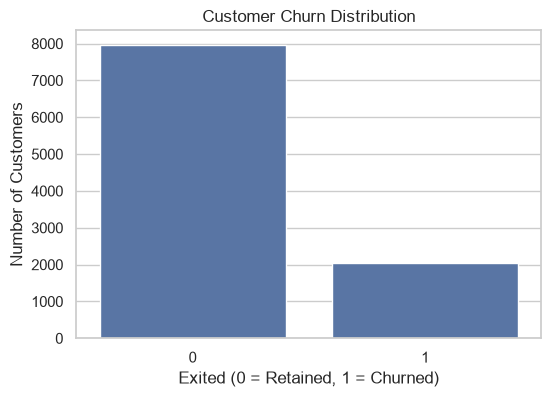

In [38]:
# Target distribution chart
plt.figure(figsize=(6,4))

sns.countplot(data=df, x = "Exited")

plt.title("Customer Churn Distribution")
plt.xlabel("Exited (0 = Retained, 1 = Churned)")
plt.ylabel("Number of Customers")

plt.show()

### Data Cleaning & Feature Preperation

In [39]:
df_clean = df.copy()

print("Original Shape", df.shape)
print("Working dataset Shape", df_clean.shape)

Original Shape (10000, 14)
Working dataset Shape (10000, 14)


In [40]:
# Validate Binary Columns

binary_columns = [
    "HasCrCard",
    "IsActiveMember",
    "Exited"
]

for col in binary_columns:
    unique_values = df_clean[col].unique()
    
    invalid_values = df_clean.loc[
        ~df_clean[col].isin([0, 1]),
        col
    ].unique()

    print(f"\n{col}")
    print("Unique values:", unique_values)
    print("Invalid values:", invalid_values)


HasCrCard
Unique values: [1 0]
Invalid values: []

IsActiveMember
Unique values: [1 0]
Invalid values: []

Exited
Unique values: [1 0]
Invalid values: []


In [41]:
# Check Numerical Variable 
numeric_columns = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "EstimatedSalary"
]

df_clean[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
CreditScore,10000.0,650.528800,96.653299,350.00,584.00,652.000,718.0000,850.00
Age,10000.0,38.921800,10.487806,18.00,32.00,37.000,44.0000,92.00
Tenure,10000.0,5.012800,2.892174,0.00,3.00,5.000,7.0000,10.00
Balance,10000.0,76485.889288,62397.405202,0.00,0.00,97198.540,127644.2400,250898.09
NumOfProducts,10000.0,1.530200,0.581654,1.00,1.00,1.000,2.0000,4.00
EstimatedSalary,10000.0,100090.239881,57510.492818,11.58,51002.11,100193.915,149388.2475,199992.48


In [42]:
# Numerical Data Validation

validation_checks = {
    "Invalid Age": (
        (df_clean["Age"] < 18) |
        (df_clean["Age"] > 100)
    ).sum(),

    "Invalid Credit Score": (
        (df_clean["CreditScore"] < 0) |
        (df_clean["CreditScore"] > 1000)
    ).sum(),

    "Invalid Tenure": (
        df_clean["Tenure"] < 0
    ).sum(),

    "Negative Balance": (
        df_clean["Balance"] < 0
    ).sum(),

    "Invalid Number of Products": (
        df_clean["NumOfProducts"] < 1
    ).sum(),

    "Negative Estimated Salary": (
        df_clean["EstimatedSalary"] < 0
    ).sum()
}

pd.Series(validation_checks, name="Invalid Records")

Invalid Age                   0
Invalid Credit Score          0
Invalid Tenure                0
Negative Balance              0
Invalid Number of Products    0
Negative Estimated Salary     0
Name: Invalid Records, dtype: int64

In [43]:
# Feature Engineering

df_clean["EngagementStatus"] = df_clean["IsActiveMember"].map({
    1: "Active",
    0: "Inactive"
})

df_clean["ProductCategory"] = np.where(
    df_clean["NumOfProducts"] == 1,
    "Single Product",
    "Multi Product"
)

df_clean["CreditCardStatus"] = df_clean["HasCrCard"].map({
    1: "Has Credit Card",
    0: "No Credit Card"
})

df_clean["ChurnStatus"] = df_clean["Exited"].map({
    1: "Churned",
    0: "Retained"
})

df_clean["BalanceSalaryRatio"] = np.where(
    df_clean["EstimatedSalary"] > 0,
    df_clean["Balance"] / df_clean["EstimatedSalary"],
    np.nan
)

df_clean.head()

,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,EngagementStatus,ProductCategory,CreditCardStatus,ChurnStatus,BalanceSalaryRatio
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,Active,Single Product,Has Credit Card,Churned,0.000000
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,Active,Single Product,No Credit Card,Retained,0.744677
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,Inactive,Multi Product,Has Credit Card,Churned,1.401375
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,Inactive,Multi Product,No Credit Card,Retained,0.000000
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,Active,Single Product,Has Credit Card,Retained,1.587055


In [44]:
# Save the Cleaned Dataset
df_clean.to_csv(
    "../data/cleaned_bank_customer.csv",
    index=False
)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


In [45]:
# Final Vaidation 
print("========== FINAL DATA CLEANING SUMMARY ==========")

print(f"Original rows          : {df.shape[0]}")
print(f"Cleaned rows           : {df_clean.shape[0]}")

print(f"Original columns       : {df.shape[1]}")
print(f"Cleaned columns        : {df_clean.shape[1]}")

print(f"Missing values         : {df_clean.isnull().sum().sum()}")
print(f"Duplicate rows         : {df_clean.duplicated().sum()}")

print(f"Churned customers      : {df_clean['Exited'].sum()}")
print(f"Retained customers     : {(df_clean['Exited'] == 0).sum()}")

========== FINAL DATA CLEANING SUMMARY ==========
Original rows          : 10000
Cleaned rows           : 10000
Original columns       : 14
Cleaned columns        : 19
Missing values         : 0
Duplicate rows         : 0
Churned customers      : 2037
Retained customers     : 7963


## Exploratory Data Analysis (EDA)

In [46]:
df = df_clean.copy()

In [47]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

### EDA PART A — Overall Customer Churn

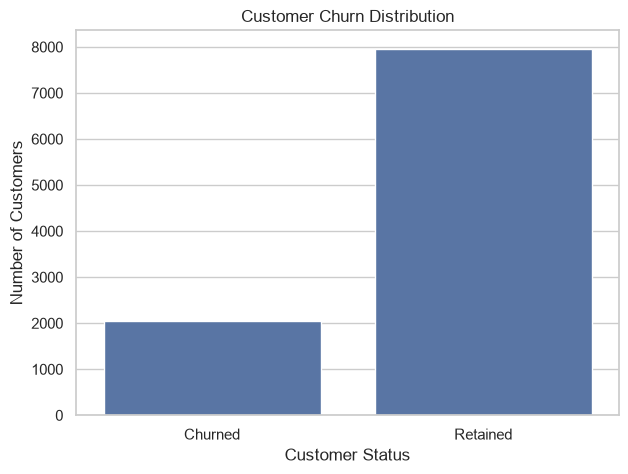

Churn / Retention Percentage:
ChurnStatus
Retained    79.63
Churned     20.37
Name: proportion, dtype: float64


In [48]:
# Overall Customer Churn

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="ChurnStatus"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

plt.show()

churn_percentage = (
    df["ChurnStatus"]
    .value_counts(normalize=True)
    .mul(100)
)

print("Churn / Retention Percentage:")
print(churn_percentage.round(2))

### Business Insights
The dataset has an overall churn rate of 20.37%, indicating that approximately one in five customers has exited the bank. This provides the baseline against which customer segments can be compared.

### EDA PART B — Geography Analysis

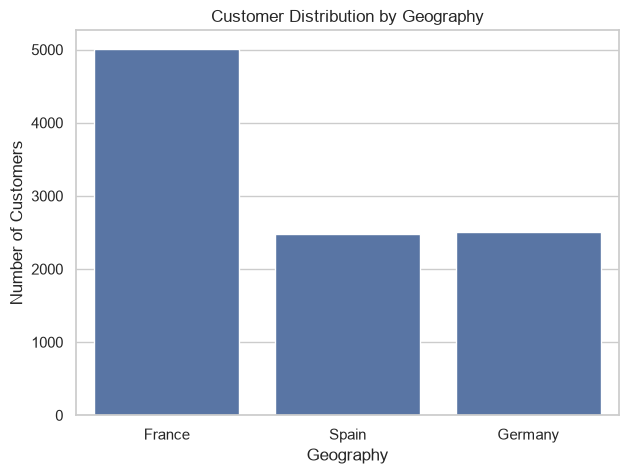

In [49]:
# Customers by Geogaphy
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Geography"
)

plt.title("Customer Distribution by Geography")
plt.xlabel("Geography")
plt.ylabel("Number of Customers")

plt.show()

Geography
Germany    32.44
Spain      16.67
France     16.15
Name: Exited, dtype: float64


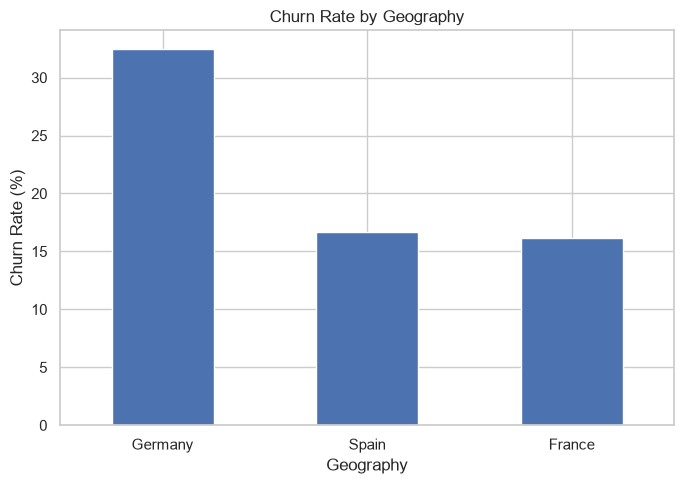

In [50]:
# Churn Rate by Geography

geo_churn = (
    df.groupby("Geography")["Exited"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(geo_churn.round(2))

plt.figure(figsize=(7, 5))

geo_churn.plot(kind="bar")

plt.title("Churn Rate by Geography")
plt.xlabel("Geography")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "../outputs/charts/churn_by_geography.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Business Insights
Germany shows the highest churn rate at approximately 32.44%, almost twice the churn rate observed in France and Spain. This indicates that geography may be an important segmentation variable for retention strategies.

### EDA PART C — Gender Analysis

Gender
Female    25.07
Male      16.46
Name: Exited, dtype: float64


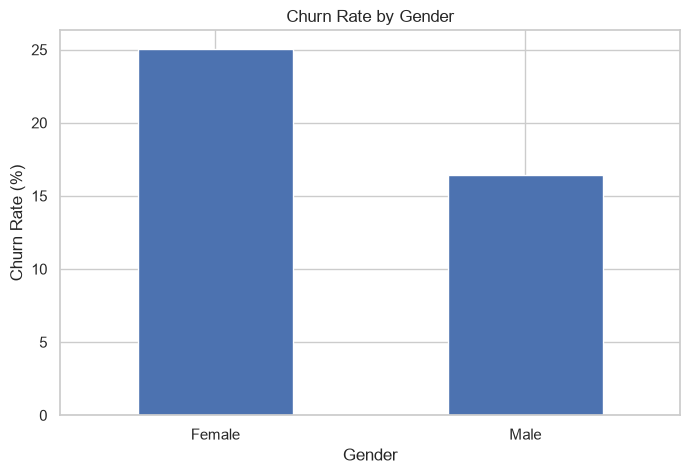

In [51]:
# Gender VS Churn
gender_churn = (
    df.groupby("Gender")["Exited"]
    .mean()
    .mul(100)
)

print(gender_churn.round(2))

gender_churn.plot(kind="bar")

plt.title("Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

### Business Insights
Female customers have a higher observed churn rate than male customers in this dataset (25.07% vs 16.46%). This difference should be investigated further alongside age, geography, engagement, and product usage rather than being treated as a standalone causal factor.

### EDA PART D — Engagement Analysis 

EngagementStatus
Inactive    26.85
Active      14.27
Name: Exited, dtype: float64


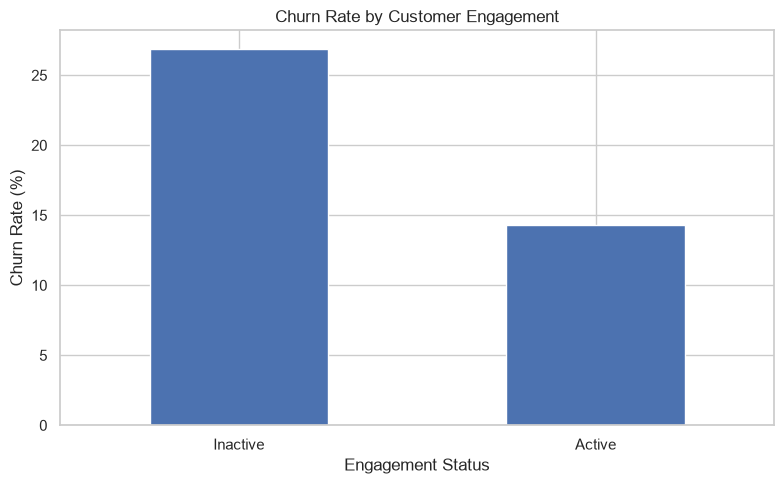

In [52]:
# Engagement vs Churn

engagement_churn = (
    df.groupby("EngagementStatus")["Exited"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(engagement_churn.round(2))

plt.figure(figsize=(8, 5))

engagement_churn.plot(kind="bar")

plt.title("Churn Rate by Customer Engagement")
plt.xlabel("Engagement Status")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()

plt.show()

### Business Insights
Inactive customers have a substantially higher churn rate (26.85%) than active customers (14.27%). This supports the project hypothesis that customer engagement is strongly associated with retention and should be incorporated into retention strategies.

### EDA PART E — Product Utilization

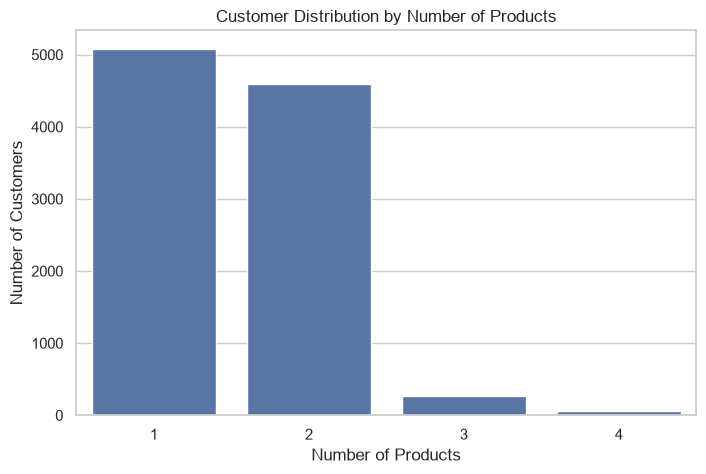

In [53]:
# Customer Distribution by Product Count
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="NumOfProducts"
)

plt.title("Customer Distribution by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Number of Customers")

plt.show()

               count   sum  ChurnRate
NumOfProducts                        
1               5084  1409      27.71
2               4590   348       7.58
3                266   220      82.71
4                 60    60     100.00


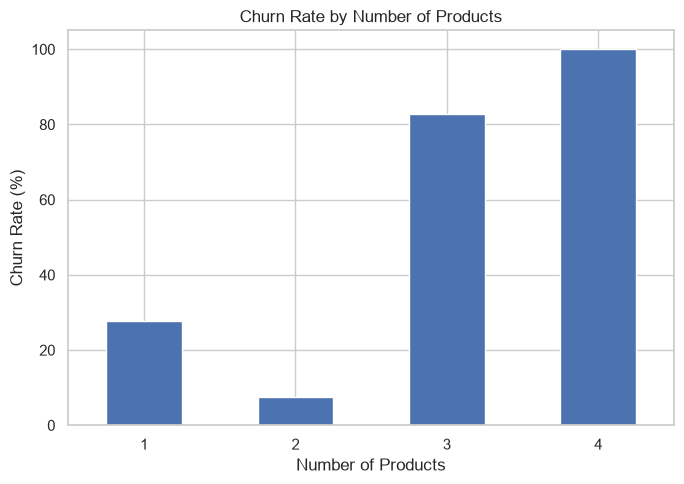

In [54]:
# Product Count vs Churn
product_churn = (
    df.groupby("NumOfProducts")["Exited"]
    .agg(["count", "sum", "mean"])
)

product_churn["ChurnRate"] = product_churn["mean"] * 100

product_churn = product_churn.drop(columns="mean")

print(product_churn.round(2))

product_churn = (
    df.groupby("NumOfProducts")["Exited"]
    .mean() * 100
)

plt.figure(figsize=(7, 5))

product_churn.plot(kind="bar")

plt.title("Churn Rate by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "../outputs/charts/churn_by_product_count.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### EDA PART F — Credit Card Analysis

CreditCardStatus
No Credit Card     20.81
Has Credit Card    20.18
Name: Exited, dtype: float64


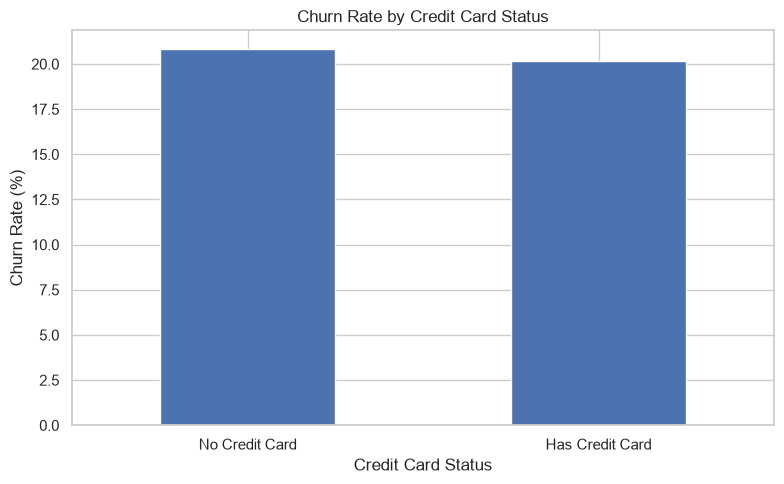

In [55]:
# Credit Card Status vs Churn

card_churn = (
    df.groupby("CreditCardStatus")["Exited"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(card_churn.round(2))

plt.figure(figsize=(8, 5))

card_churn.plot(kind="bar")

plt.title("Churn Rate by Credit Card Status")
plt.xlabel("Credit Card Status")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Business Insights
Credit-card ownership shows only a small difference in observed churn rates in this dataset (20.18% for card holders vs 20.82% for non-card holders). Therefore, credit-card ownership alone does not appear to be a strong retention indicator.

### EDA PART G — Age Analysis

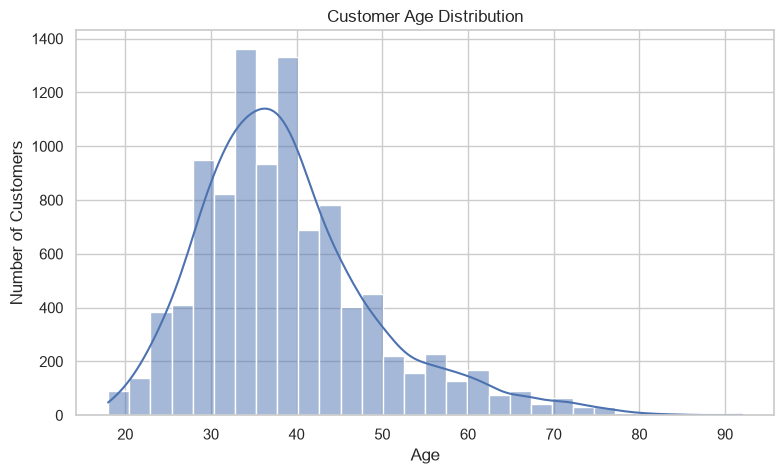

In [56]:
# Age Distribution
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=30,
    kde=True
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

In [57]:
# Age Groups
age_bins = [18, 25, 35, 45, 55, 65, 101]

age_labels = [
    "18-24",
    "25-34",
    "35-44",
    "45-54",
    "55-64",
    "65+"
]

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

AgeGroup
18-24     8.75
25-34     7.76
35-44    17.66
45-54    48.15
55-64    49.83
65+      15.25
Name: Exited, dtype: float64


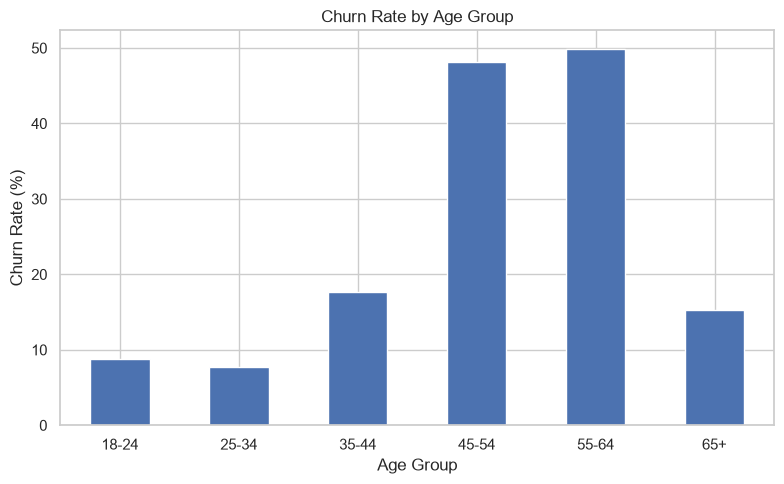

In [58]:
# Age Group vs Churn
age_churn = (
    df.groupby("AgeGroup", observed=False)["Exited"]
    .mean()
    .mul(100)
)

print(age_churn.round(2))

age_churn.plot(kind="bar")

plt.title("Churn Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "../outputs/charts/churn_by_age_group.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Bisiness Insigts
Customers aged 45–64 show substantially higher observed churn rates, with approximately 48.15% churn for ages 45–54 and 49.83% for ages 55–64. This segment should receive particular attention in retention analysis.

### EDA PART H — Credit Score

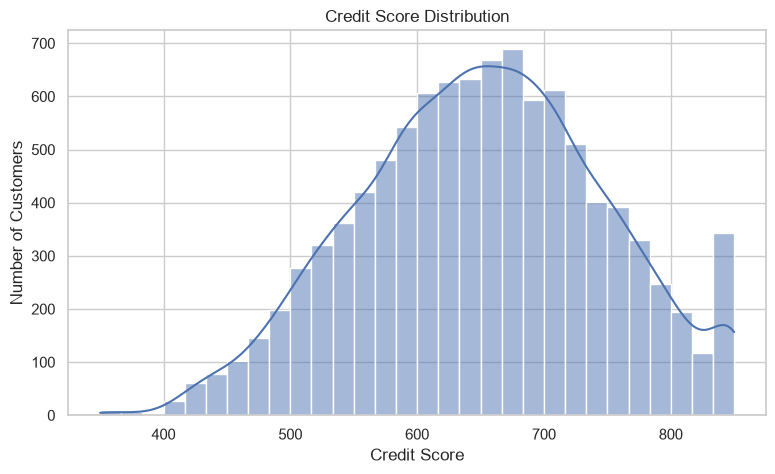

In [59]:
# Credit Score Distribution
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="CreditScore",
    bins=30,
    kde=True
)

plt.title("Credit Score Distribution")
plt.xlabel("Credit Score")
plt.ylabel("Number of Customers")

plt.show()

CreditScoreGroup
<500       23.73
500-599    21.23
600-699    19.72
700-799    19.90
800+       19.54
Name: Exited, dtype: float64


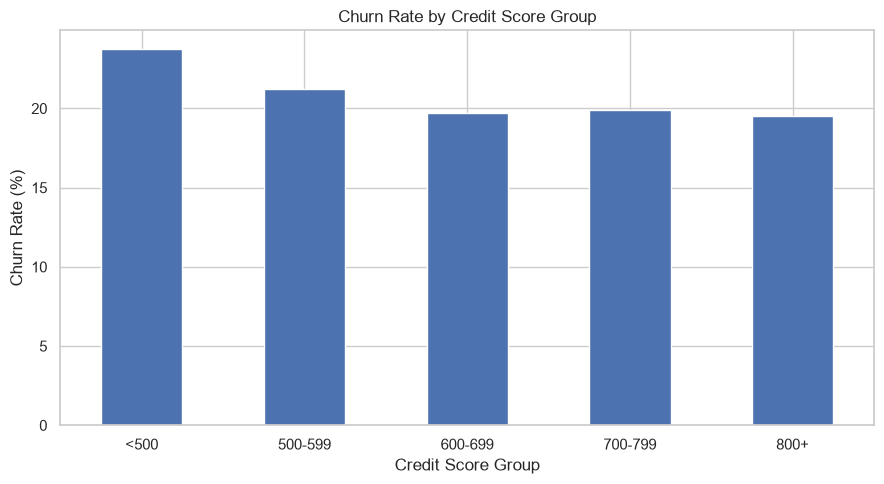

In [60]:
# Credit Score Group vs Churn

credit_bins = [0, 500, 600, 700, 800, 1001]

credit_labels = [
    "<500",
    "500-599",
    "600-699",
    "700-799",
    "800+"
]

df["CreditScoreGroup"] = pd.cut(
    df["CreditScore"],
    bins=credit_bins,
    labels=credit_labels,
    right=False
)

credit_churn = (
    df.groupby(
        "CreditScoreGroup",
        observed=False
    )["Exited"]
    .mean()
    .mul(100)
)

print(credit_churn.round(2))

plt.figure(figsize=(9, 5))

credit_churn.plot(kind="bar")

plt.title("Churn Rate by Credit Score Group")
plt.xlabel("Credit Score Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Business Insights
Credit score shows a relatively modest relationship with churn compared with engagement and age. Customers with credit scores below 500 have a 23.73% churn rate versus approximately 19.54% among customers with scores of 800 or above.

### EDA PART I — Tenure

Churn Rate by Tenure:
Tenure
0     23.00
1     22.42
2     19.18
3     21.11
4     20.53
5     20.65
6     20.27
7     17.22
8     19.22
9     21.65
10    20.61
Name: Exited, dtype: float64


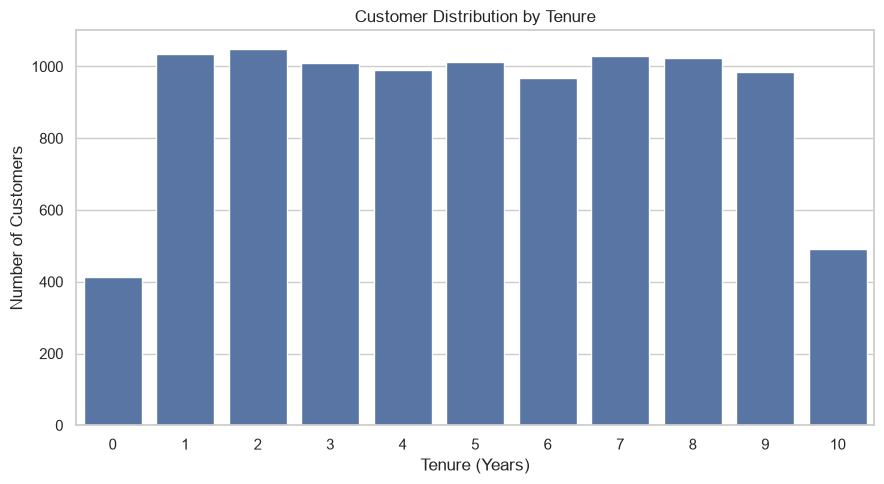

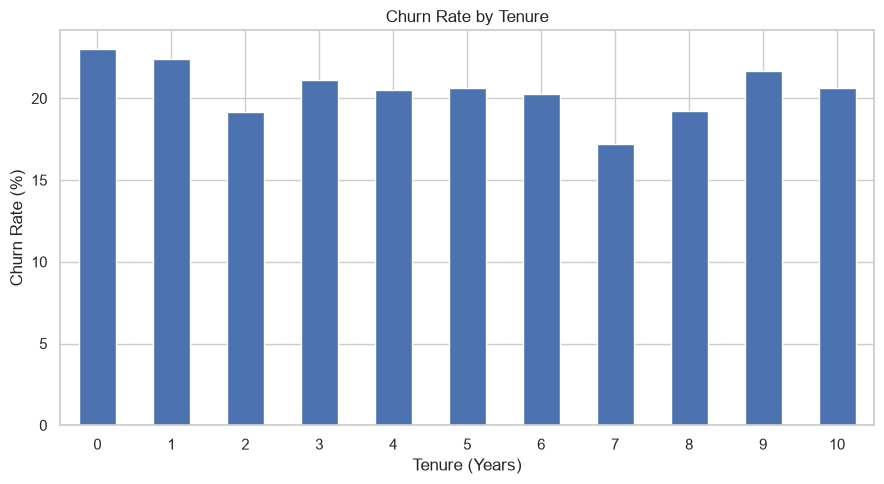

In [61]:
# Tenure Analysis

tenure_churn = (
    df.groupby("Tenure")["Exited"]
    .mean()
    .mul(100)
)

print("Churn Rate by Tenure:")
print(tenure_churn.round(2))

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Tenure"
)

plt.title("Customer Distribution by Tenure")
plt.xlabel("Tenure (Years)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))

tenure_churn.plot(kind="bar")

plt.title("Churn Rate by Tenure")
plt.xlabel("Tenure (Years)")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Business Insights
Tenure alone does not show a consistent linear relationship with churn in this dataset.

### EDA PART J — Balance

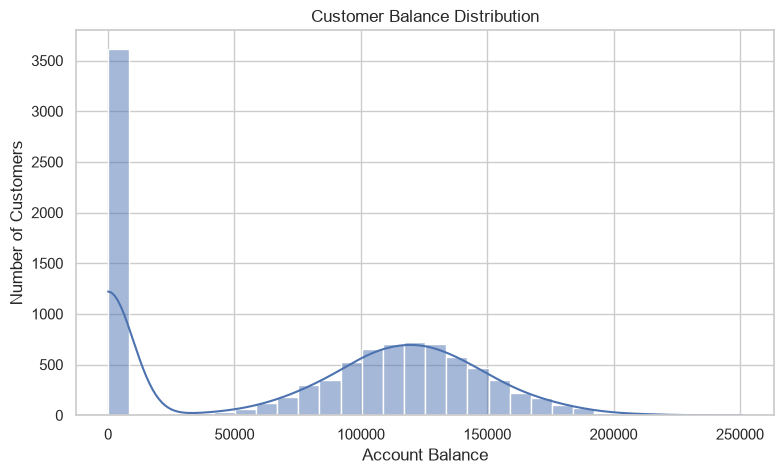

In [62]:
# Balance Distribution
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Balance",
    bins=30,
    kde=True
)

plt.title("Customer Balance Distribution")
plt.xlabel("Account Balance")
plt.ylabel("Number of Customers")

plt.show()

             count      mean     median  min        max
ChurnStatus                                            
Churned       2037  91108.54  109349.29  0.0  250898.09
Retained      7963  72745.30   92072.68  0.0  221532.80


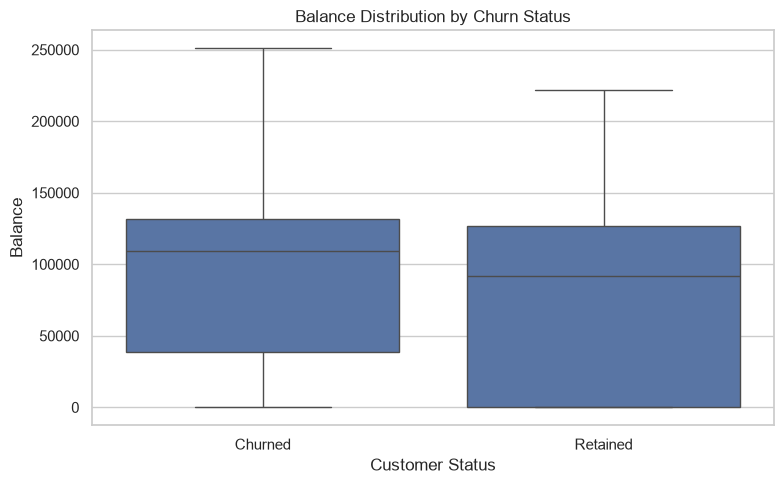

In [63]:
# Balance Analysis

balance_summary = (
    df.groupby("ChurnStatus")["Balance"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        min="min",
        max="max"
    )
)

print(balance_summary.round(2))

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="ChurnStatus",
    y="Balance"
)

plt.title("Balance Distribution by Churn Status")
plt.xlabel("Customer Status")
plt.ylabel("Balance")

plt.tight_layout()
plt.show()

### EDA PART K — Estimated Salary

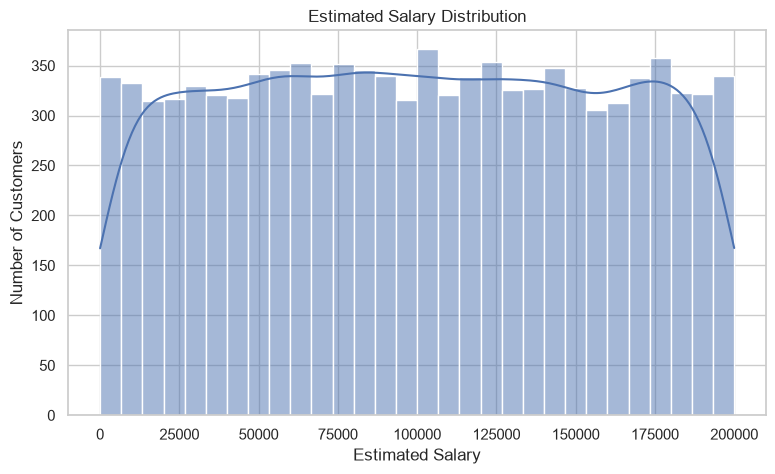

In [64]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="EstimatedSalary",
    bins=30,
    kde=True
)

plt.title("Estimated Salary Distribution")
plt.xlabel("Estimated Salary")
plt.ylabel("Number of Customers")

plt.show()

             count      mean     median  min        max
ChurnStatus                                            
Churned       2037  91108.54  109349.29  0.0  250898.09
Retained      7963  72745.30   92072.68  0.0  221532.80


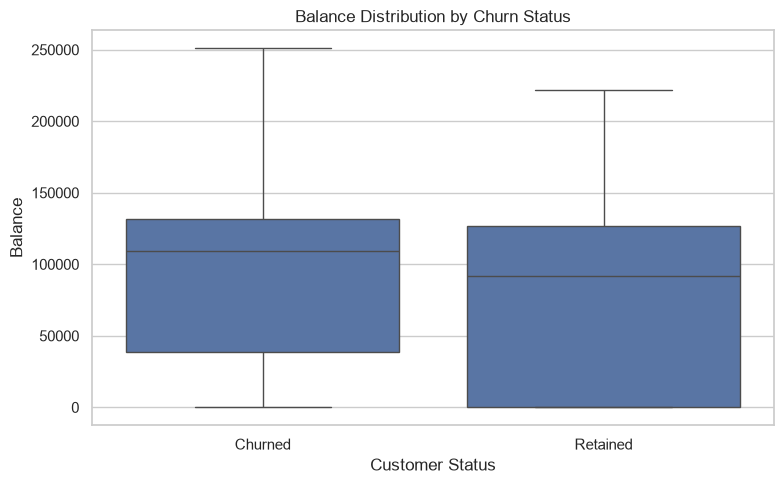

In [65]:
# Balance Analysis

balance_summary = (
    df.groupby("ChurnStatus")["Balance"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        min="min",
        max="max"
    )
)

print(balance_summary.round(2))

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="ChurnStatus",
    y="Balance"
)

plt.title("Balance Distribution by Churn Status")
plt.xlabel("Customer Status")
plt.ylabel("Balance")

plt.tight_layout()
plt.show()

### EDA PART L — Important Correlation Matrix

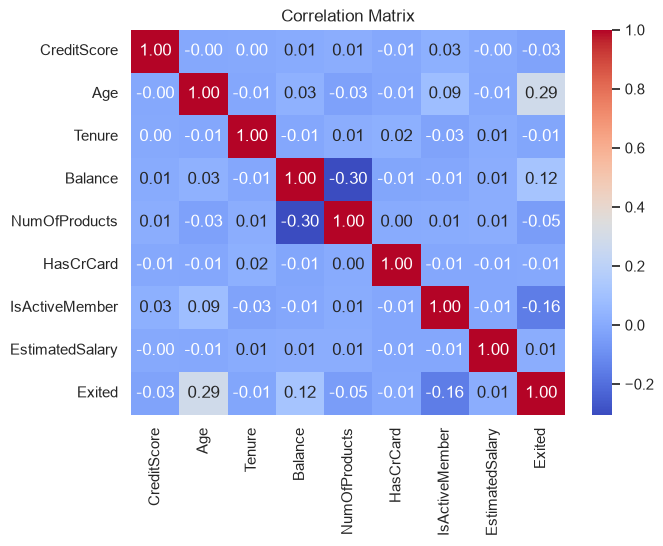

In [66]:
numeric_cols = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary",
    "Exited"
]

correlation = df[numeric_cols].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.show()

### EDA PART M — Engagement + Product Combination

EngagementStatus  Active  Inactive
ProductCategory                   
Multi Product       9.66     16.24
Single Product     18.92     36.65


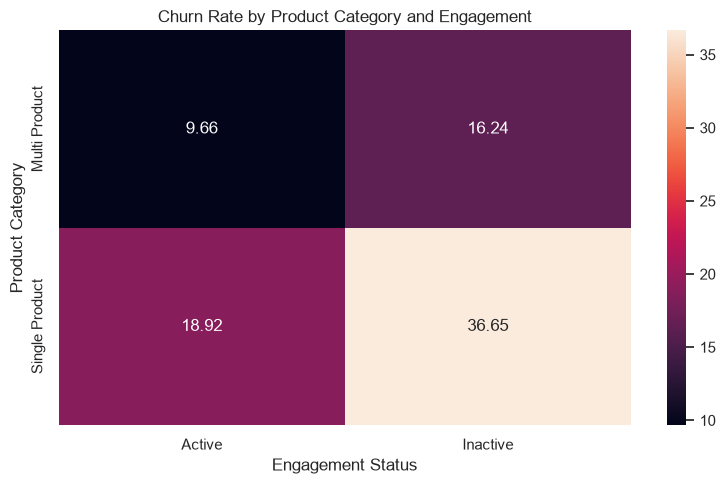

In [67]:
engagement_product = pd.crosstab(
    df["ProductCategory"],
    df["EngagementStatus"],
    values=df["Exited"],
    aggfunc="mean"
) * 100

print(engagement_product.round(2))

plt.figure(figsize=(8, 5))

sns.heatmap(
    engagement_product,
    annot=True,
    fmt=".2f"
)

plt.title("Churn Rate by Product Category and Engagement")
plt.xlabel("Engagement Status")
plt.ylabel("Product Category")

plt.tight_layout()

plt.savefig(
    "../outputs/charts/churn_product_engagement_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### EDA PART N — High Balance + Inactive

In [68]:
# High-Value Disengaged Customers

balance_threshold = df["Balance"].quantile(0.75)

high_value_disengaged = df[
    (df["Balance"] >= balance_threshold) &
    (df["IsActiveMember"] == 0)
].copy()

churn_rate = high_value_disengaged["Exited"].mean() * 100

print("High Balance Threshold:", round(balance_threshold, 2))
print("High-value disengaged customers:", len(high_value_disengaged))
print("Churn Rate:", round(churn_rate, 2), "%")

High Balance Threshold: 127644.24
High-value disengaged customers: 1247
Churn Rate: 30.47 %


In [69]:
# High-Value Customer Table
high_value_disengaged[
    [
        "CustomerId",
        "Geography",
        "Age",
        "Balance",
        "NumOfProducts",
        "HasCrCard",
        "IsActiveMember",
        "Exited"
    ]
].head(20)

,CustomerId,Geography,Age,Balance,NumOfProducts,HasCrCard,IsActiveMember,Exited
2,15619304,France,42,159660.80,3,1,0,1
16,15737452,Germany,58,132602.88,1,1,0,1
35,15794171,France,45,134264.04,1,1,0,1
43,15755196,France,49,131394.56,1,0,0,1
51,15768193,Germany,36,146050.97,2,0,0,0
56,15630053,France,45,127864.40,1,1,0,0
60,15651280,Germany,35,136857.00,1,0,0,0
61,15773469,Germany,27,152328.88,2,0,0,0
70,15703793,Germany,58,133745.44,4,1,0,1
75,15780961,France,21,178718.19,2,1,0,0


1️⃣ Engagement

Inactive customers have a much higher churn rate than active customers: 26.85% vs 14.27%.

2️⃣ Age

Customers aged 45–64 show very high observed churn, around 48–50%.

3️⃣ Geography

Germany has the highest observed churn rate at 32.44%, compared with around 16%–17% in France and Spain.

4️⃣ Product Depth

Customers with two products show substantially lower churn than single-product customers, while the 3- and 4-product groups are small and require cautious interpretation.

### Test Source file

In [70]:
import sys

sys.path.append("../src")

from analysis import (
    calculate_overall_churn,
    churn_by_geography,
    churn_by_gender,
    churn_by_engagement,
    churn_by_product_count,
    churn_by_credit_card,
    churn_by_age_group,
    churn_by_credit_score_group
)

In [71]:
# Create an Analysis Summary Table
summary_tables = {
    "Geography": churn_by_geography(df),
    "Gender": churn_by_gender(df),
    "Engagement": churn_by_engagement(df),
    "Product": churn_by_product_count(df),
    "Credit Card": churn_by_credit_card(df)
}

for name, table in summary_tables.items():
    print(f"\n========== {name} ==========")
    print(table.round(2))


========== Geography ==========
  Geography  CustomerCount  ChurnedCustomers  ChurnRate
0    France           5014               810      16.15
1   Germany           2509               814      32.44
2     Spain           2477               413      16.67

========== Gender ==========
   Gender  CustomerCount  ChurnedCustomers  ChurnRate
0  Female           4543              1139      25.07
1    Male           5457               898      16.46

========== Engagement ==========
  EngagementStatus  CustomerCount  ChurnedCustomers  ChurnRate
0           Active           5151               735      14.27
1         Inactive           4849              1302      26.85

========== Product ==========
   NumOfProducts  CustomerCount  ChurnedCustomers  ChurnRate
0              1           5084              1409      27.71
1              2           4590               348       7.58
2              3            266               220      82.71
3              4             60                60    

In [72]:
# Export Analysis Table
# Geography
geo_analysis = churn_by_geography(df)

geo_analysis.to_csv(
    "../outputs/tables/geography_churn.csv",
    index=False)

# Engagement
engagement_analysis = churn_by_engagement(df)

engagement_analysis.to_csv(
    "../outputs/tables/engagement_churn.csv",
    index=False
)

# Product
product_analysis = churn_by_product_count(df)

product_analysis.to_csv(
    "../outputs/tables/product_churn.csv",
    index=False
)

# Age
age_analysis = churn_by_age_group(df)

age_analysis.to_csv(
    "../outputs/tables/age_churn.csv",
    index=False
)

# Credit Score
credit_analysis = churn_by_credit_score_group(df)

credit_analysis.to_csv(
    "../outputs/tables/credit_score_churn.csv",
    index=False
)


### Retention Risk Analysis

In [73]:
from scoring import calculate_retention_risk_score

risk_df = calculate_retention_risk_score(df)

print("========== RETENTION RISK SUMMARY ==========")

print(
    risk_df[
        [
            "RetentionRiskScore",
            "RiskCategory"
        ]
    ].head(10)
)

print("\nRisk Category Distribution:")
print(
    risk_df["RiskCategory"]
    .value_counts()
    .sort_index()
)

print("\nRetention Priority Distribution:")
print(
    risk_df["RetentionPriority"]
    .value_counts()
)

========== RETENTION RISK SUMMARY ==========
   RetentionRiskScore RiskCategory
0                   2     Low Risk
1                   2     Low Risk
2                   5  Medium Risk
3                   3  Medium Risk
4                   2     Low Risk
5                   3  Medium Risk
6                   1     Low Risk
7                   4  Medium Risk
8                   0     Low Risk
9                   2     Low Risk

Risk Category Distribution:
RiskCategory
Low Risk       4098
Medium Risk    4100
High Risk      1802
Name: count, dtype: int64

Retention Priority Distribution:
RetentionPriority
Normal      4839
Medium      3914
High         629
Critical     618
Name: count, dtype: int64


In [74]:
risk_validation = (
    risk_df
    .groupby("RiskCategory", observed=True)["Exited"]
    .agg(
        CustomerCount="count",
        ChurnedCustomers="sum",
        ChurnRate="mean"
    )
    .reset_index()
)

risk_validation["ChurnRate"] = (
    risk_validation["ChurnRate"] * 100
)

risk_validation

,RiskCategory,CustomerCount,ChurnedCustomers,ChurnRate
0,Low Risk,4098,394,9.614446
1,Medium Risk,4100,833,20.317073
2,High Risk,1802,810,44.950055


In [75]:
high_value_disengaged = risk_df[
    (risk_df["HighValueCustomer"] == True) &
    (risk_df["IsActiveMember"] == 0)
].copy()

print(
    "High-value disengaged customers:",
    len(high_value_disengaged)
)

high_value_disengaged[
    [
        "CustomerId",
        "Surname",
        "Geography",
        "Age",
        "Balance",
        "NumOfProducts",
        "IsActiveMember",
        "RetentionRiskScore",
        "RiskCategory",
        "RetentionPriority",
        "Exited"
    ]
].head(10)

High-value disengaged customers: 1247


,CustomerId,Surname,Geography,Age,Balance,NumOfProducts,IsActiveMember,RetentionRiskScore,RiskCategory,RetentionPriority,Exited
2,15619304,Onio,France,42,159660.80,3,0,5,Medium Risk,High,1
16,15737452,Romeo,Germany,58,132602.88,1,0,9,High Risk,Critical,1
35,15794171,Lombardo,France,45,134264.04,1,0,8,High Risk,Critical,1
43,15755196,Lavine,France,49,131394.56,1,0,8,High Risk,Critical,1
51,15768193,Trevisani,Germany,36,146050.97,2,0,6,High Risk,Critical,0
56,15630053,Tsao,France,45,127864.40,1,0,8,High Risk,Critical,0
60,15651280,Hunter,Germany,35,136857.00,1,0,8,High Risk,Critical,0
61,15773469,Clark,Germany,27,152328.88,2,0,6,High Risk,Critical,0
70,15703793,Konovalova,Germany,58,133745.44,4,0,7,High Risk,Critical,1
75,15780961,Cavenagh,France,21,178718.19,2,0,5,Medium Risk,High,0


In [76]:
high_value_disengaged.to_csv(
    "../outputs/tables/high_value_disengaged_customers.csv",
    index=False
)

risk_validation.to_csv(
    "../outputs/tables/risk_score_validation.csv",
    index=False
)

### Final KPIs and Business Finding Table

In [82]:
# Final KPI Summary

from kpi import (
    engagement_retention_ratio,
    product_depth_index,
    high_balance_disengagement_rate,
    credit_card_stickiness_score,
    relationship_strength_index
)

final_err = engagement_retention_ratio(df)
final_pdi = product_depth_index(df)
final_hbdr = high_balance_disengagement_rate(df)
final_ccs = credit_card_stickiness_score(df)

rsi_df = relationship_strength_index(df)

final_balance_threshold = df["Balance"].quantile(0.75)

final_kpi_table = pd.DataFrame({
    "KPI": [
        "Engagement Retention Ratio",
        "Product Depth Index",
        "High-Balance Disengagement Rate",
        "Credit Card Stickiness Score"
    ],

    "Value": [
        round(final_err, 2),
        round(final_pdi, 2),
        round(final_hbdr, 2),
        round(final_ccs, 2)
    ],

    "Interpretation": [
        "Retention comparison between active and inactive customers",
        "Retention comparison between multi-product and single-product customers",
        "Percentage of high-balance customers who are inactive",
        "Retention comparison between credit-card and non-credit-card customers"
    ]
})

print("========== FINAL KPI SUMMARY ==========")
display(final_kpi_table)

print("\nRelationship Strength Distribution:")
display(
    rsi_df["RelationshipStrengthCategory"]
    .value_counts()
)

========== FINAL KPI SUMMARY ==========


,KPI,Value,Interpretation
0,Engagement Retention Ratio,1.17,Retention comparison between active and inacti...
1,Product Depth Index,1.21,Retention comparison between multi-product and...
2,High-Balance Disengagement Rate,49.88,Percentage of high-balance customers who are i...
3,Credit Card Stickiness Score,1.01,Retention comparison between credit-card and n...



Relationship Strength Distribution:


RelationshipStrengthCategory
Moderate    4557
Strong      2767
Weak        2676
Name: count, dtype: int64

In [ ]:
# Save KPI Table
final_kpi_table.to_csv(
    "../outputs/tables/final_kpi_summary.csv",
    index=False
)

In [ ]:
# FINAL PROJECT SUMMARY

final_summary = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Retained Customers",
        "Churned Customers",
        "Retention Rate (%)",
        "Churn Rate (%)",
        "High-Balance Threshold"
    ],
    
    "Value": [
        len(df),
        int((df["Exited"] == 0).sum()),
        int(df["Exited"].sum()),
        round((df["Exited"] == 0).mean() * 100, 2),
        round(df["Exited"].mean() * 100, 2),
        round(final_balance_threshold, 2)
    ]
})

final_summary

,Metric,Value
0,Total Customers,10000.00
1,Retained Customers,7963.00
2,Churned Customers,2037.00
3,Retention Rate (%),79.63
4,Churn Rate (%),20.37
5,High-Balance Threshold,127644.24


In [ ]:
# Save Final Project Summay Table
final_summary.to_csv(
    "../outputs/tables/final_project_summary.csv",
    index=False
)

### Final Segment Finding

In [ ]:
# Final Segment Findings

final_geography = (
    df.groupby("Geography")["Exited"]
    .agg(
        CustomerCount="count",
        ChurnRate="mean"
    )
    .reset_index()
)

final_geography["ChurnRate"] *= 100


final_engagement = (
    df.groupby("EngagementStatus")["Exited"]
    .agg(
        CustomerCount="count",
        ChurnRate="mean"
    )
    .reset_index()
)

final_engagement["ChurnRate"] *= 100


final_product = (
    df.groupby("NumOfProducts")["Exited"]
    .agg(
        CustomerCount="count",
        ChurnRate="mean"
    )
    .reset_index()
)

final_product["ChurnRate"] *= 100


final_age = (
    df.groupby("AgeGroup", observed=True)["Exited"]
    .agg(
        CustomerCount="count",
        ChurnRate="mean"
    )
    .reset_index()
)

final_age["ChurnRate"] *= 100


print("========== GEOGRAPHY ==========")
display(final_geography)

print("========== ENGAGEMENT ==========")
display(final_engagement)

print("========== PRODUCT ==========")
display(final_product)

print("========== AGE ==========")
display(final_age)

========== GEOGRAPHY ==========


,Geography,CustomerCount,ChurnRate
0,France,5014,16.154767
1,Germany,2509,32.443204
2,Spain,2477,16.673395


========== ENGAGEMENT ==========


,EngagementStatus,CustomerCount,ChurnRate
0,Active,5151,14.269074
1,Inactive,4849,26.850897


========== PRODUCT ==========


,NumOfProducts,CustomerCount,ChurnRate
0,1,5084,27.714398
1,2,4590,7.581699
2,3,266,82.706767
3,4,60,100.000000


========== AGE ==========


,AgeGroup,CustomerCount,ChurnRate
0,18-24,457,8.752735
1,25-34,3222,7.759156
2,35-44,3981,17.658880
3,45-54,1458,48.148148
4,55-64,600,49.833333
5,65+,282,15.248227


## Final Business Findings

### 1. Overall Customer Churn

The analysis of 10,000 banking customers shows an overall
historical churn rate of 20.37%, while 79.63% of customers
were retained. This indicates that approximately one in five
customers in the analyzed population had exited the bank.

### 2. Customer Engagement and Churn

Inactive customers exhibited a substantially higher historical
churn rate than active customers. The churn rate was 26.85% for
inactive customers compared with 14.27% for active customers.
This shows that customer engagement is an important retention
indicator.

### 3. Geographic Churn Pattern

Germany had the highest historical churn rate among the three
geographic segments, with a churn rate of 32.44%. Spain and
France showed lower churn rates of 16.67% and 16.16% respectively.
This indicates that the German customer segment requires further
retention analysis.

### 4. Product Utilization and Churn

Customers with two products showed a substantially lower
historical churn rate of 7.58% compared with 27.71% for customers
with one product. However, the very high churn rates observed
among customers with three and four products should be interpreted
cautiously because these groups contain relatively few customers.
Therefore, the relationship between product depth and churn is
non-linear in this dataset.

### 5. Age and Churn

Customers aged 45–64 demonstrated substantially higher historical
churn rates than younger customer segments. The churn rate was
48.15% for customers aged 45–54 and 49.83% for customers aged
55–64. These age groups represent important segments for further
retention analysis.

### 6. High-Value Disengaged Customers

The High-Balance Disengagement Rate was 49.88%, meaning that
approximately half of the customers above the high-balance
threshold were inactive. This represents a potential high-value
retention opportunity for the bank.

### 7. Credit Card Ownership and Retention

Credit card ownership showed only a marginal difference in
historical churn. Customers with a credit card had a churn rate
of approximately 20.18%, compared with 20.82% for customers
without a credit card. Therefore, credit card ownership alone
is not a strong standalone retention indicator in this dataset.

### Overall Business Conclusion

The analysis suggests that customer engagement, product
utilization, age, geography and financial value are useful
dimensions for customer retention analysis. In particular,
inactive and high-value customers should receive greater
attention through targeted engagement and retention strategies.

## Retention Strategies

### 1. Re-engage Inactive Customers

**Target Customers:** Customers who are currently inactive.

**Finding:** Inactive customers showed a substantially higher
historical churn rate of 26.85% compared with 14.27% for active
customers.

**Recommended Action:** Develop proactive re-engagement campaigns
through email, mobile banking notifications and personalized
relationship-manager communication. Monitor changes in customer
activity and product usage.

**Expected Business Benefit:** Increased customer engagement and
potential reduction in churn among disengaged customers.

---

### 2. Increase Meaningful Product Utilization

**Target Customers:** Customers using only one banking product.

**Finding:** Single-product customers had a historical churn rate
of 27.71%, while two-product customers had a much lower churn rate
of 7.58%.

**Recommended Action:** Identify suitable additional products
for single-product customers based on their existing relationship
and needs. Examples may include savings, deposits, loans or other
relevant banking services.

**Expected Business Benefit:** Stronger customer relationships and
greater product utilization.

---

### 3. Prioritize High-Value Disengaged Customers

**Target Customers:** Customers with high balances who are inactive.

**Finding:** The High-Balance Disengagement Rate was 49.88%,
indicating that a substantial proportion of high-balance customers
were inactive.

**Recommended Action:** Create a priority retention list for
high-value disengaged customers. Assign high-priority customers
for personalized relationship-manager follow-up and engagement
review.

**Expected Business Benefit:** Protect valuable customer
relationships and reduce the risk of losing financially important
customers.

---

### 4. Use Risk-Based Retention Prioritization

**Target Customers:** Customers classified as High Risk or
Critical Priority by the analyst-developed retention scoring model.

**Finding:** The retention risk score combines observable customer
characteristics such as engagement, product depth, balance,
age-group and geography.

**Recommended Action:** Use the risk score to prioritize retention
resources. Critical customers should receive immediate attention,
while high and medium-risk customers can be targeted through
appropriate engagement programs.

**Expected Business Benefit:** More efficient allocation of
retention resources toward customers requiring greater attention.

---

### 5. Strengthen Engagement Among Customers Aged 45–64

**Target Customers:** Customers aged 45–64.

**Finding:** Customers aged 45–54 and 55–64 showed historical
churn rates of 48.15% and 49.83% respectively.

**Recommended Action:** Provide personalized communication,
relationship-manager support, service follow-ups and relevant
financial-product reviews for customers in these age groups.

**Expected Business Benefit:** Improve customer engagement and
identify retention opportunities within high-churn age segments.

---

### 6. Focus on High-Churn Geographic Segments

**Target Customers:** Customers in higher-churn geographic segments,
particularly Germany.

**Finding:** Germany showed the highest historical churn rate of
32.44%, compared with 16.67% in Spain and 16.16% in France.

**Recommended Action:** Conduct a deeper analysis of customer
experience, service quality, product usage and engagement patterns
within the German segment. Develop localized retention campaigns
based on identified customer needs.

**Expected Business Benefit:** Improve retention in the geographic
segment showing the highest historical churn.

---

### 7. Strengthen Customer Relationships

**Target Customers:** Customers with weak or moderate Relationship
Strength scores.

**Finding:** The analyst-developed Relationship Strength Index
combines engagement, product depth, credit card ownership, tenure
and balance.

**Recommended Action:** Identify weak relationship customers and
design targeted engagement activities such as product education,
service follow-ups and personalized offers.

**Expected Business Benefit:** Improve relationship depth and
increase long-term customer engagement.

---

### Overall Retention Strategy

The bank should adopt a segmented retention approach rather than
using a single strategy for all customers. Priority should be given
to inactive customers, high-value disengaged customers, high-churn
segments and customers with weaker observable relationships.

Retention actions should be personalized according to customer
needs, engagement level, product usage and financial value.